# Độ chính xác của bỏ phiếu đa số theo số bộ phân loại độc lập (mục 9.2.1)

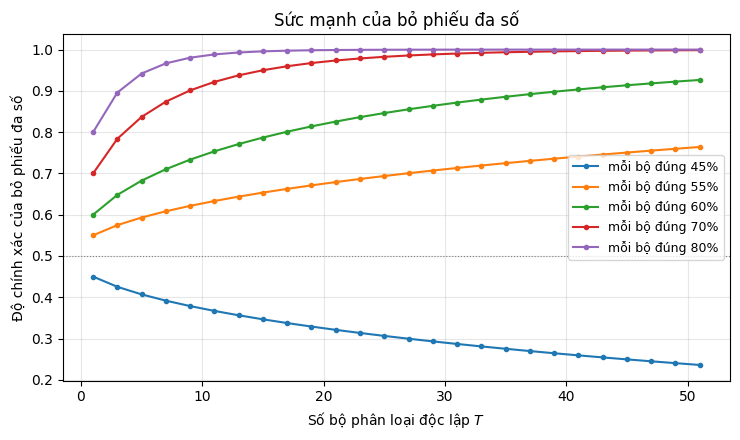

In [1]:
from math import comb
from pathlib import Path

import matplotlib.pyplot as plt

IMAGES = Path('.')   # thư mục images/ (notebook chạy trong images/)

def majority_vote_accuracy(T, p):
    """Xác suất hơn một nửa trong T bộ phân loại độc lập (mỗi bộ đúng với xác suất p) cùng đúng."""
    return sum(comb(T, k) * p**k * (1 - p)**(T - k) for k in range(T // 2 + 1, T + 1))

T_values = list(range(1, 52, 2))             # số lẻ để không hòa phiếu
fig, ax = plt.subplots(figsize=(7.5, 4.5))
for p in [0.45, 0.55, 0.6, 0.7, 0.8]:
    ax.plot(T_values, [majority_vote_accuracy(T, p) for T in T_values], 'o-', ms=3,
            label='mỗi bộ đúng %d%%' % round(100 * p))
ax.axhline(0.5, color='gray', lw=0.8, ls=':')
ax.set_xlabel('Số bộ phân loại độc lập $T$')
ax.set_ylabel('Độ chính xác của bỏ phiếu đa số')
ax.set_title('Sức mạnh của bỏ phiếu đa số')
ax.legend(fontsize=9); ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(IMAGES / 'majority_vote.png', dpi=150)